# Tech Challenge — Fase 4 | Voz do Cliente: Olist e RAG

A proposta deste trabalho é investigar as avaliações de clientes da Olist por meio de perguntas em linguagem natural. Primeiro, relaciono os comentários aos pedidos e preparo os textos. Depois, comparo três formas de encontrar avaliações semelhantes à pergunta: **TF-IDF, LSA e MiniLM**. Por fim, uso o **Ollama (Llama 3.2)** para resumir as evidências recuperadas com citações.

O objetivo não é adivinhar o que aconteceu com os clientes. É permitir que cada resposta seja conferida nos comentários originais.

> **Como ler este notebook:** as saídas das execuções anteriores foram preservadas. Ao executar todas as células novamente, os resultados serão recalculados com as configurações e comparações descritas abaixo.


## 1. Importações e caminhos

Os dados originais ficam no arquivo `data/raw/olist_dataset_original.zip`. Os arquivos gerados ficam em `data/processed`, `artifacts` e `results`. O caminho é identificado a partir da pasta do projeto para funcionar tanto no VS Code quanto no Jupyter.


In [1]:
from pathlib import Path
import sys
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ = Path.cwd()
if RAIZ.name == 'notebooks':
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

ORIGEM = RAIZ / 'data' / 'raw'
DESTINO = RAIZ / 'data' / 'processed'
ZIP = ORIGEM / 'olist_dataset_original.zip'
DESTINO.mkdir(parents=True, exist_ok=True)
assert ZIP.exists(), 'Coloque o ZIP em data/raw/olist_dataset_original.zip'
print('Pasta do projeto:', RAIZ)

Pasta do projeto: c:\Users\Gui\Downloads\tech_challenge_fase4_luiz_e_victor


## 2. Leitura das bases originais

Descompactei somente as **sete tabelas usadas** na análise. Depois li cada CSV com `pd.read_csv()`. A Olist também tem geolocalização e vendedores, mas não precisamos dessas duas tabelas para investigar o conteúdo das avaliações.

A primeira verificação é conferir a quantidade de registros e a chave principal de cada base.

In [2]:
nomes_arquivos = [
    'olist_order_reviews_dataset.csv',
    'olist_orders_dataset.csv',
    'olist_customers_dataset.csv',
    'olist_order_items_dataset.csv',
    'olist_products_dataset.csv',
    'product_category_name_translation.csv',
    'olist_order_payments_dataset.csv'
]

with zipfile.ZipFile(ZIP) as arquivo_zip:
    for nome in nomes_arquivos:
        if not (ORIGEM / nome).exists():
            arquivo_zip.extract(nome, ORIGEM)

avaliacoes = pd.read_csv(ORIGEM / 'olist_order_reviews_dataset.csv')
pedidos = pd.read_csv(ORIGEM / 'olist_orders_dataset.csv')
clientes = pd.read_csv(ORIGEM / 'olist_customers_dataset.csv')
itens = pd.read_csv(ORIGEM / 'olist_order_items_dataset.csv')
produtos = pd.read_csv(ORIGEM / 'olist_products_dataset.csv')
categorias = pd.read_csv(ORIGEM / 'product_category_name_translation.csv')
pagamentos = pd.read_csv(ORIGEM / 'olist_order_payments_dataset.csv')

quantidades = pd.DataFrame({
    'base': ['avaliações', 'pedidos', 'clientes', 'itens', 'produtos', 'categorias', 'pagamentos'],
    'linhas': [len(avaliacoes), len(pedidos), len(clientes), len(itens),
               len(produtos), len(categorias), len(pagamentos)]
})
display(quantidades)

,base,linhas
0,avaliações,99224
1,pedidos,99441
2,clientes,99441
3,itens,112650
4,produtos,32951
5,categorias,71
6,pagamentos,103886


## 3. Como as tabelas se relacionam

O ponto de partida é a avaliação, identificada por `review_id`, e o **pedido** é a ligação principal.

```text
avaliações ── order_id ──► pedidos ── customer_id ──► clientes
                              │
                              ├── order_id ──► itens ── product_id ──► produtos ──► categorias
                              │
                              └── order_id ──► pagamentos
```

| Tabelas | Chave | Relacionamento | Cuidado |
|---|---|---|---|
| Pedidos → clientes | `customer_id` | Muitos pedidos? Na Olist, um registro de cliente por pedido | `many_to_one` |
| Itens → produtos | `product_id` | Vários itens podem usar o mesmo produto | `many_to_one` |
| Produtos → categorias | `product_category_name` | Muitas referências à mesma categoria | `many_to_one` |
| Pedidos → itens | `order_id` | Um pedido pode ter vários itens | **Agrupar antes do merge** |
| Pedidos → pagamentos | `order_id` | Um pedido pode ter vários pagamentos | **Agrupar antes do merge** |
| Avaliações → pedidos | `order_id` | Cada avaliação pertence a um pedido | `many_to_one` |

Por que agrupar antes? Se um pedido tem **2 itens e 2 pagamentos**, um `merge()` direto criaria **4 linhas** para o mesmo pedido. Para evitar esse erro, deixei uma linha por pedido em `itens_por_pedido` e `pagamentos_por_pedido`.

## 4. Limpeza dos comentários

Como o objetivo é estudar textos, avaliações sem título **e** sem comentário são removidas. Eu mantive a nota e as chaves para conseguir localizar cada avaliação na base de origem.

Não removi pontuação nem palavras comuns: elas podem ajudar a interpretar o sentido dos comentários.

In [3]:
avaliacoes['titulo'] = avaliacoes['review_comment_title'].fillna('').astype(str).str.strip()
avaliacoes['comentario'] = avaliacoes['review_comment_message'].fillna('').astype(str).str.strip()

avaliacoes['titulo'] = avaliacoes['titulo'].str.replace(r'\s+', ' ', regex=True)
avaliacoes['comentario'] = avaliacoes['comentario'].str.replace(r'\s+', ' ', regex=True)
avaliacoes['texto'] = (avaliacoes['titulo'] + '. ' + avaliacoes['comentario']).str.strip(' .')

avaliacoes_texto = avaliacoes[avaliacoes['texto'].str.len() >= 3].copy()
avaliacoes_texto = avaliacoes_texto.drop_duplicates(subset=['review_id', 'order_id'])

print('Avaliações originais:', len(avaliacoes))
print('Avaliações que possuem texto, sem duplicidades:', len(avaliacoes_texto))
display(avaliacoes_texto[['review_id', 'order_id', 'review_score', 'texto']].head(3))

Avaliações originais: 99224
Avaliações que possuem texto, sem duplicidades: 42343


,review_id,order_id,review_score,texto
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,Recebi bem antes do prazo estipulado
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,Parabéns lojas lannister adorei comprar pela I...
9,8670d52e15e00043ae7de4c01cc2fe06,b9bf720beb4ab3728760088589c62129,4,recomendo. aparelho eficiente. no site a marca...


## 5. Cruzamento dos itens com produtos e categorias

Cada item tem um `product_id`. Uso essa coluna para trazer sua categoria e depois traduzi-la para inglês, pois a tabela auxiliar já oferece essa descrição.

In [4]:
itens_produtos = itens.merge(
    produtos[['product_id', 'product_category_name']],
    on='product_id', how='left', validate='many_to_one'
)

itens_produtos = itens_produtos.merge(
    categorias,
    on='product_category_name', how='left', validate='many_to_one'
)

itens_produtos['categoria'] = (
    itens_produtos['product_category_name_english']
    .fillna(itens_produtos['product_category_name'])
    .fillna('não informada')
)

assert len(itens_produtos) == len(itens), 'O merge dos produtos multiplicou linhas!'
print('Itens antes e depois das junções:', len(itens), '→', len(itens_produtos))
display(itens_produtos[['order_id', 'product_id', 'categoria', 'price']].head(3))

Itens antes e depois das junções: 112650 → 112650


,order_id,product_id,categoria,price
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,58.9
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,pet_shop,239.9
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,furniture_decor,199.0


## 6. Resumo dos itens e dos pagamentos por pedido

A partir daqui o objetivo é ter **uma linha por `order_id`**. Uso `groupby()` para somar valores e contar itens.

Para não perder pedidos com categorias diferentes, guardo os nomes das categorias separados por `|` 

In [5]:
itens_por_pedido = itens_produtos.groupby('order_id', as_index=False).agg(
    qtd_itens=('order_item_id', 'count'),
    valor_produtos=('price', 'sum'),
    valor_frete=('freight_value', 'sum')
)

categorias_por_pedido = (itens_produtos.groupby('order_id')['categoria']
    .apply(lambda serie: ' | '.join(sorted(serie.dropna().unique())))
    .reset_index(name='categorias'))

itens_por_pedido = itens_por_pedido.merge(
    categorias_por_pedido, on='order_id', how='left', validate='one_to_one'
)

pagamentos_por_pedido = (pagamentos.groupby('order_id', as_index=False)
    .agg(valor_pago=('payment_value', 'sum')))

assert itens_por_pedido['order_id'].is_unique
assert pagamentos_por_pedido['order_id'].is_unique
print('Pedidos com itens:', len(itens_por_pedido))
print('Pedidos com pagamentos:', len(pagamentos_por_pedido))
display(itens_por_pedido.head(3))

Pedidos com itens: 98666
Pedidos com pagamentos: 99440


,order_id,qtd_itens,valor_produtos,valor_frete,categorias
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.9,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,239.9,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,199.0,17.87,furniture_decor


## 7. Cruzamento de pedidos com clientes, itens e pagamentos

O pedido é a nossa tabela central. Cada `merge()` adiciona um assunto:

1. **Clientes:** cidade e estado.
2. **Itens resumidos:** quantidade, preço, frete e categorias.
3. **Pagamentos resumidos:** valor total pago.

O `validate` verifica a cardinalidade de cada relacionamento.

In [6]:
pedidos_completos = pedidos.merge(
    clientes[['customer_id', 'customer_city', 'customer_state']],
    on='customer_id', how='left', validate='many_to_one'
)
print('Após juntar clientes:', len(pedidos_completos))

pedidos_completos = pedidos_completos.merge(
    itens_por_pedido, on='order_id', how='left', validate='one_to_one'
)
print('Após juntar itens:', len(pedidos_completos))

pedidos_completos = pedidos_completos.merge(
    pagamentos_por_pedido, on='order_id', how='left', validate='one_to_one'
)
print('Após juntar pagamentos:', len(pedidos_completos))

assert len(pedidos_completos) == len(pedidos)
assert pedidos_completos['order_id'].is_unique

Após juntar clientes: 99441
Após juntar itens: 99441
Após juntar pagamentos: 99441


## 8. Datas de entrega e base final de avaliações

Converto duas datas para calcular o atraso: `dias_atraso > 0` indica entrega posterior à data estimada. Quando não existe entrega, esse campo fica vazio; não suponho que o pedido atrasou.

Por fim, junto **avaliações com texto** aos **pedidos completos** usando `order_id`. Esta é a tabela que alimenta a busca do RAG.

In [7]:
pedidos_completos['order_purchase_timestamp'] = pd.to_datetime(
    pedidos_completos['order_purchase_timestamp'], errors='coerce')
pedidos_completos['order_delivered_customer_date'] = pd.to_datetime(
    pedidos_completos['order_delivered_customer_date'], errors='coerce')
pedidos_completos['order_estimated_delivery_date'] = pd.to_datetime(
    pedidos_completos['order_estimated_delivery_date'], errors='coerce')

pedidos_completos['dias_atraso'] = (
    pedidos_completos['order_delivered_customer_date'] -
    pedidos_completos['order_estimated_delivery_date']
).dt.days

colunas_pedido = [
    'order_id', 'order_status', 'order_purchase_timestamp',
    'customer_city', 'customer_state', 'qtd_itens',
    'valor_produtos', 'valor_frete', 'valor_pago', 'categorias', 'dias_atraso'
]

documentos = avaliacoes_texto.merge(
    pedidos_completos[colunas_pedido],
    on='order_id', how='left', validate='many_to_one'
)

documentos['ano_compra'] = documentos['order_purchase_timestamp'].dt.year
documentos['categorias'] = documentos['categorias'].fillna('não informada')
documentos['id_documento'] = documentos['review_id'] + '|' + documentos['order_id']

colunas_finais = [
    'id_documento', 'review_id', 'order_id', 'review_score', 'texto',
    'review_creation_date', 'ano_compra', 'categorias', 'order_status',
    'dias_atraso', 'customer_city', 'customer_state', 'qtd_itens',
    'valor_produtos', 'valor_frete', 'valor_pago'
]
documentos = documentos[colunas_finais].reset_index(drop=True)

assert len(documentos) == len(avaliacoes_texto)
assert documentos['id_documento'].is_unique
assert documentos['texto'].str.len().ge(3).all()

print('Avaliações com texto:', len(avaliacoes_texto))
print('Avaliações após o merge:', len(documentos))
display(documentos[['review_score', 'texto', 'categorias', 'dias_atraso']].head(4))

Avaliações com texto: 42343
Avaliações após o merge: 42343


,review_score,texto,categorias,dias_atraso
0,5,Recebi bem antes do prazo estipulado,garden_tools,-20.0
1,5,Parabéns lojas lannister adorei comprar pela I...,sports_leisure,-9.0
2,4,recomendo. aparelho eficiente. no site a marca...,small_appliances,-16.0
3,4,"Mas um pouco ,travando...pelo valor ta Boa",health_beauty,-11.0


## 9. Salvando as bases tratadas

Salvo três tabelas em CSV compactado (`.csv.gz`), que o Pandas lê normalmente com `pd.read_csv()`. A partir delas podemos refazer análises sem repetir todas as junções.

- `itens_enriquecidos`: item + produto + categoria.
- `pedidos_relacionados`: pedido + cliente + resumo de itens e pagamentos.
- `avaliacoes_tratadas`: um documento por avaliação com texto, com os metadados para o RAG.

In [8]:
itens_produtos.to_csv(DESTINO / 'itens_enriquecidos.csv.gz', index=False)
pedidos_completos.to_csv(DESTINO / 'pedidos_relacionados.csv.gz', index=False)
documentos.to_csv(DESTINO / 'avaliacoes_tratadas.csv.gz', index=False)

validacao = pd.DataFrame([
    ['Avaliações na origem', len(avaliacoes)],
    ['Avaliações com texto', len(avaliacoes_texto)],
    ['Pedidos na origem', len(pedidos)],
    ['Pedidos após os merges', len(pedidos_completos)],
    ['Documentos para o RAG', len(documentos)]
], columns=['Etapa', 'Linhas'])
display(validacao)
assert len(pd.read_csv(DESTINO / 'avaliacoes_tratadas.csv.gz')) == len(documentos)

,Etapa,Linhas
0,Avaliações na origem,99224
1,Avaliações com texto,42343
2,Pedidos na origem,99441
3,Pedidos após os merges,99441
4,Documentos para o RAG,42343


## 10. Entendendo as avaliações com uma análise simples

Antes de usar NLP, verifiquei a distribuição das notas. Isso ajuda a explicar por que um comentário positivo não deve ser tratado como reclamação apenas por citar a palavra "entrega".

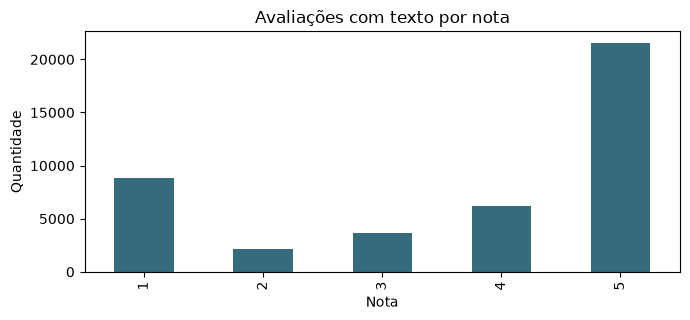

Avaliações nota 1 ou 2: 10971


In [9]:
distribuicao_notas = documentos['review_score'].value_counts().sort_index()
ax = distribuicao_notas.plot(kind='bar', figsize=(7, 3.3), color='#356b7b')
ax.set(title='Avaliações com texto por nota', xlabel='Nota', ylabel='Quantidade')
plt.tight_layout()
(RAIZ / 'images').mkdir(exist_ok=True)
plt.savefig(RAIZ / 'images' / 'notas_avaliacoes.png', dpi=150)
plt.show()
print('Avaliações nota 1 ou 2:', int(documentos['review_score'].le(2).sum()))

## 11. Preparação do TF-IDF e do LSA

O **TF-IDF** representa os textos a partir das palavras e expressões presentes nas avaliações. O **LSA** aplica uma redução de dimensionalidade sobre essa matriz, produzindo uma representação menor dos documentos.

Mantive os dois métodos porque eles permitem observar um ponto importante: reduzir os vetores nem sempre melhora o retorno dos comentários para a pergunta feita. O MiniLM será incluído na mesma comparação, com os mesmos documentos e filtros.


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

vetorizador = TfidfVectorizer(
    strip_accents='unicode', max_features=12000, min_df=2,
    ngram_range=(1, 2)
)
matriz_tfidf = vetorizador.fit_transform(documentos['texto'])

redutor = TruncatedSVD(n_components=64, n_iter=3, random_state=42)
embeddings_lsa = normalize(redutor.fit_transform(matriz_tfidf)).astype('float32')

indice_tfidf = {
    'metodo': 'tfidf', 'dados': documentos,
    'tfidf': vetorizador, 'vetores': matriz_tfidf
}
indice_lsa = {
    'metodo': 'lsa', 'dados': documentos,
    'tfidf': vetorizador, 'lsa': redutor, 'vetores': embeddings_lsa
}

print('TF-IDF (documentos x termos):', matriz_tfidf.shape)
print('Embeddings LSA (documentos x dimensões):', embeddings_lsa.shape)
(RAIZ / 'artifacts').mkdir(exist_ok=True)
np.save(RAIZ / 'artifacts' / 'embeddings_lsa.npy', embeddings_lsa)


TF-IDF (documentos x termos): (42343, 12000)
Embeddings LSA (documentos x dimensões): (42343, 64)


## 12. Primeira comparação: TF-IDF e LSA

Comecei com três perguntas sobre **atraso**, **produto quebrado** e **embalagem**. A verificação abaixo conta quantos dos cinco comentários recuperados incluem expressões relacionadas ao tema. Isso ajuda a identificar diferenças, mas **não é uma medida definitiva de relevância**: um comentário pode falar sobre o assunto sem usar essas palavras.

Depois de preparar o MiniLM, repito a comparação com os três métodos em uma única tabela. Assim, todos são avaliados com as mesmas perguntas e o mesmo filtro de notas.


In [11]:
from src.rag_simples import buscar, responder, criar_contexto

perguntas_teste = [
    ('atraso', 'Quais reclamações existem sobre atraso na entrega?', ['atras', 'demor', 'prazo']),
    ('quebrado', 'Os clientes reclamam de produtos quebrados?', ['quebrad', 'danific', 'avari']),
    ('embalagem', 'Há reclamações sobre embalagens dos produtos?', ['embalag', 'caixa', 'empacot']),
]

linhas_iniciais = []
for tema, pergunta_teste, palavras in perguntas_teste:
    for nome, indice_temp in [('TF-IDF', indice_tfidf), ('LSA', indice_lsa)]:
        encontrados = buscar(pergunta_teste, indice_temp, k=5, nota_max=2)
        com_termo = sum(any(p in e['texto'].lower() for p in palavras)
                        for e in encontrados)
        linhas_iniciais.append({
            'tema': tema, 'busca': nome, 'comentarios': len(encontrados),
            'com_termos_do_tema': com_termo
        })
comparacao_inicial = pd.DataFrame(linhas_iniciais)
display(comparacao_inicial)

print('Exemplos encontrados para produtos quebrados:')
for titulo, indice_temp in [('TF-IDF', indice_tfidf), ('LSA', indice_lsa)]:
    print('\n' + titulo)
    for item in buscar('Os clientes reclamam de produtos quebrados?', indice_temp,
                       k=2, nota_max=2):
        print('-', item['texto'][:180])


,tema,busca,comentarios,com_termos_do_tema
0,atraso,TF-IDF,5,5
1,atraso,LSA,5,5
2,quebrado,TF-IDF,5,1
3,quebrado,LSA,5,0
4,embalagem,TF-IDF,5,1
5,embalagem,LSA,5,0


Exemplos encontrados para produtos quebrados:

TF-IDF
- tablets quebrados. alguns tablets de bcaa vieram quebrados, diminuindo a qualidade do produto
- Anúncio e venda de produtos indisponíveis

LSA
- muitos desencontros nas entregas de produtos
- Anúncio e venda de produtos indisponíveis


## 13. MiniLM e comparação dos três métodos

Também utilizei o **MiniLM multilíngue**, um modelo pré-treinado que transforma frases em vetores e permite buscar textos semanticamente próximos. Não foi necessário treinar uma rede neural com os comentários da Olist.

Nesta etapa, o notebook prepara o índice MiniLM e reaproveita os embeddings salvos quando existe um registro que confirma que foram gerados a partir da mesma base. Se a base tiver mudado, recalcula os vetores para evitar comparar comentários com embeddings desalinhados.

A tabela seguinte coloca **TF-IDF, LSA e MiniLM lado a lado**, usando as mesmas três perguntas, cinco resultados por método e avaliações de nota 1 ou 2. A contagem de termos funciona como um indicador exploratório; a qualidade semântica ainda precisa ser avaliada lendo os comentários.


In [12]:
import hashlib
import json

USAR_MINILM = True
indice_minilm = None
indice_rag = indice_tfidf

if USAR_MINILM:
    try:
        from sentence_transformers import SentenceTransformer
    except ImportError as erro:
        raise ImportError(
            'Falta instalar o MiniLM. Execute: pip install -r requirements-minilm.txt'
        ) from erro

    nome_modelo = 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'
    modelo_minilm = SentenceTransformer(nome_modelo)
    cache_minilm = RAIZ / 'artifacts' / 'embeddings_minilm.npy'
    arquivo_controle = RAIZ / 'artifacts' / 'embeddings_minilm_controle.json'

    # A assinatura identifica a ordem dos documentos e o texto de cada avaliação.
    assinatura = hashlib.sha256()
    for identificador, texto in zip(documentos['id_documento'], documentos['texto']):
        assinatura.update(str(identificador).encode('utf-8'))
        assinatura.update(b'\0')
        assinatura.update(str(texto).encode('utf-8'))
        assinatura.update(b'\n')
    hash_base = assinatura.hexdigest()

    usar_cache = False
    if cache_minilm.exists() and arquivo_controle.exists():
        controle = json.loads(arquivo_controle.read_text(encoding='utf-8'))
        usar_cache = (controle.get('hash_base') == hash_base
                      and controle.get('modelo') == nome_modelo)

    if usar_cache:
        embeddings_minilm = np.load(cache_minilm, allow_pickle=False)
        usar_cache = (embeddings_minilm.ndim == 2
                      and len(embeddings_minilm) == len(documentos)
                      and embeddings_minilm.shape[1] == (modelo_minilm.get_embedding_dimension() if hasattr(modelo_minilm, 'get_embedding_dimension') else modelo_minilm.get_sentence_embedding_dimension()))

    if not usar_cache:
        embeddings_minilm = modelo_minilm.encode(
            documentos['texto'].tolist(), batch_size=64,
            show_progress_bar=True, normalize_embeddings=True
        )
        np.save(cache_minilm, embeddings_minilm)
        arquivo_controle.write_text(json.dumps({
            'hash_base': hash_base, 'modelo': nome_modelo,
            'documentos': len(documentos)
        }, indent=2), encoding='utf-8')
        print('Embeddings MiniLM gerados para esta versão da base.')
    else:
        print('Embeddings MiniLM conferidos e carregados do cache.')

    indice_minilm = {
        'metodo': 'minilm', 'dados': documentos,
        'modelo': modelo_minilm, 'vetores': embeddings_minilm
    }
    indice_rag = indice_minilm

print('Método usado na recuperação do RAG:', indice_rag['metodo'])


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embeddings MiniLM conferidos e carregados do cache.
Método usado na recuperação do RAG: minilm


In [13]:
import unicodedata

# Normalizo acentos e maiúsculas apenas na contagem de expressões.
def normalizar_texto(texto):
    texto = unicodedata.normalize('NFKD', str(texto).lower())
    return ''.join(letra for letra in texto if not unicodedata.combining(letra))

indices_busca = {'TF-IDF': indice_tfidf, 'LSA': indice_lsa, 'MiniLM': indice_minilm}
linhas_comparacao = []
resultados_por_busca = {}

for tema, pergunta_teste, palavras in perguntas_teste:
    for nome, indice_temp in indices_busca.items():
        if indice_temp is None:
            continue
        encontrados = buscar(pergunta_teste, indice_temp, k=5, nota_max=2)
        resultados_por_busca[(tema, nome)] = encontrados
        qtd_termos = sum(any(p in normalizar_texto(e['texto']) for p in palavras)
                        for e in encontrados)
        linhas_comparacao.append({
            'tema': tema,
            'metodo': nome,
            'retornados': len(encontrados),
            'com_termos_do_tema': qtd_termos,
            'proporcao_lexical_pct': round(100 * qtd_termos / len(encontrados), 1)
                if encontrados else 0,
            'reviews': ' | '.join(e['review_id'] for e in encontrados),
        })

comparacao = pd.DataFrame(linhas_comparacao)
(RAIZ / 'results').mkdir(exist_ok=True)
comparacao.to_csv(RAIZ / 'results' / 'comparacao_buscas.csv', index=False)
display(comparacao.drop(columns='reviews'))

print('\nResumo por método:')
resumo_buscas = comparacao.groupby('metodo', as_index=False).agg(
    comentarios=('retornados', 'sum'),
    com_termos=('com_termos_do_tema', 'sum')
)
resumo_buscas['proporcao_lexical_pct'] = (
    100 * resumo_buscas['com_termos'] / resumo_buscas['comentarios'].replace(0, np.nan)
).round(1)
display(resumo_buscas)

print('\nLeitura do teste: esses números mostram presença de palavras nos comentários')
print('recuperados, não precisão semântica comprovada nem superioridade geral de um modelo.')

# Exemplos reais para conferir se o indicador lexical faz sentido.
for tema, _, _ in perguntas_teste:
    print('\nTema:', tema)
    for metodo in indices_busca:
        exemplos = resultados_por_busca.get((tema, metodo), [])[:2]
        print(metodo + ':', ' | '.join(e['texto'][:110] for e in exemplos) or 'nenhum comentário')


,tema,metodo,retornados,com_termos_do_tema,proporcao_lexical_pct
0,atraso,TF-IDF,5,5,100.0
1,atraso,LSA,5,5,100.0
2,atraso,MiniLM,5,5,100.0
3,quebrado,TF-IDF,5,1,20.0
4,quebrado,LSA,5,0,0.0
5,quebrado,MiniLM,5,1,20.0
6,embalagem,TF-IDF,5,1,20.0
7,embalagem,LSA,5,0,0.0
8,embalagem,MiniLM,5,2,40.0



Resumo por método:


,metodo,comentarios,com_termos,proporcao_lexical_pct
0,LSA,15,5,33.3
1,MiniLM,15,8,53.3
2,TF-IDF,15,7,46.7



Leitura do teste: esses números mostram presença de palavras nos comentários
recuperados, não precisão semântica comprovada nem superioridade geral de um modelo.

Tema: atraso
TF-IDF: Atraso na entrega | ATRASO NA ENTREGA. ATRASO NA ENTREGA
LSA: Atraso na entrega | ATRASO NA ENTREGA. ATRASO NA ENTREGA
MiniLM: Gostaria de esclarecimentos acerca da entrega que está em atraso | demora na entrega

Tema: quebrado
TF-IDF: tablets quebrados. alguns tablets de bcaa vieram quebrados, diminuindo a qualidade do produto | Anúncio e venda de produtos indisponíveis
LSA: muitos desencontros nas entregas de produtos | Anúncio e venda de produtos indisponíveis
MiniLM: Produto entregue não condiz com o produto comprado, péssima qualidade, assessório veio quebrado | Produto veio com defeito. Antes de recomendar a loja preciso ver se a loja irá trocar o produto que veio com d

Tema: embalagem
TF-IDF: recebi 2 dos 3 produtos desejados | Faltaram duas embalagens
LSA: Quero saber dos demais produtos eram 3 

### Como interpretar a comparação

A tabela acima é o resultado da última execução. A contagem mostra quantos comentários do top 5 contêm as expressões escolhidas para cada tema, não quantos comentários foram considerados relevantes por um avaliador. Um texto que diga “veio com defeito”, por exemplo, pode ser útil para a pergunta sobre produto quebrado mesmo sem conter a raiz “quebrad”. Os gráficos do final são recalculados a cada execução e facilitam comparar os métodos.


## 14. Preparando as evidências para o RAG

A recuperação é feita com o MiniLM, depois de comparar seu comportamento com TF-IDF e LSA. Cada resultado mantém `review_id`, `order_id`, nota e texto original, além de um marcador como `[E1]`.

Esses marcadores servem para conferir de onde veio cada afirmação. Eles **não garantem, por si só, que a interpretação esteja correta**; é preciso ler os trechos citados.


In [14]:
pergunta = 'O que os clientes relatam sobre entrega atrasada?'
evidencias = buscar(pergunta, indice_rag, k=5, nota_max=2)
print('Pergunta:', pergunta)

if evidencias:
    display(pd.DataFrame(evidencias)[['fonte', 'review_id', 'nota', 'similaridade', 'texto']])
    print('\nContexto recuperado para o modelo:\n')
    print(criar_contexto(evidencias)[:2200])
else:
    print('Nenhum comentário atingiu o limite de similaridade definido.')

assert len(evidencias) >= 2, 'Não foram encontradas avaliações suficientes neste exemplo.'


Pergunta: O que os clientes relatam sobre entrega atrasada?


,fonte,review_id,nota,similaridade,texto
0,E1,7c4c2d10a57d4aab58a570a5a8ac9f2c,1,0.828,Gostaria de esclarecimentos acerca da entrega ...
1,E2,7eaac7481400e495ddfc2f5398aba896,1,0.781,A entrega esta atrasada
2,E3,8f9772ae7dec3db4af0418fd7fb1be4d,1,0.767,Produto com entrega atrasada
3,E4,9f5600c5ab1457f1ec08b2ea6720cf49,1,0.759,entrega muito atrasada
4,E5,7528a396f7625967f05cb09946286608,1,0.758,Ultimamente estão atrasando muito as entregas



Contexto recuperado para o modelo:

[E1] Nota 1/5, review_id=7c4c2d10a57d4aab58a570a5a8ac9f2c, order_id=e269b2472c0546324acf4d09dd7acfab: Gostaria de esclarecimentos acerca da entrega que está em atraso
[E2] Nota 1/5, review_id=7eaac7481400e495ddfc2f5398aba896, order_id=fc303e9e3e6717098dbf0a3484304832: A entrega esta atrasada
[E3] Nota 1/5, review_id=8f9772ae7dec3db4af0418fd7fb1be4d, order_id=4882f3ba2955233931dbfa02945db130: Produto com entrega atrasada
[E4] Nota 1/5, review_id=9f5600c5ab1457f1ec08b2ea6720cf49, order_id=952da942e2586c7131de1381aba049a3: entrega muito atrasada
[E5] Nota 1/5, review_id=7528a396f7625967f05cb09946286608, order_id=1777854e00599d581f88f45af1432949: Ultimamente estão atrasando muito as entregas


## 15. Comparando a consulta de evidências com a resposta do Ollama

Nesta etapa uso a **mesma pergunta e o mesmo índice MiniLM** de duas formas. Primeiro mostro os comentários recuperados, sem gerar texto. Depois consulto o **Llama 3.2 pelo Ollama**, enviando apenas esses comentários como contexto.

O ganho esperado do Ollama é organizar os relatos em uma resposta mais fácil de ler. A diferença precisa aparecer na saída: `RAG com Ollama` significa que houve geração com citações aceitas pelo código; `consulta de evidências` significa que não houve uma resposta válida do modelo nessa tentativa.

O Ollama deve estar em execução com `llama3.2:3b` instalado. Se houver falha de conexão ou de citações, o resultado é mostrado como uma falha da etapa de geração, sem ser confundido com resposta do LLM.


In [15]:
resultado_evidencias = responder(
    pergunta, indice_rag, usar_ollama=False, nota_max=2
)
print('Modo:', resultado_evidencias['modo'])
print(resultado_evidencias['resposta'])


Modo: consulta de evidências
Avaliações recuperadas (sem síntese gerada por LLM):
[E1] Gostaria de esclarecimentos acerca da entrega que está em atraso (nota 1/5)
[E2] A entrega esta atrasada (nota 1/5)
[E3] Produto com entrega atrasada (nota 1/5)
[E4] entrega muito atrasada (nota 1/5)
[E5] Ultimamente estão atrasando muito as entregas (nota 1/5)


In [16]:
USAR_OLLAMA = True
resultado_ollama = responder(
    pergunta, indice_rag, usar_ollama=USAR_OLLAMA, nota_max=2
)
print('Modo:', resultado_ollama['modo'])
print('Resposta:')
print(resultado_ollama['resposta'])
if resultado_ollama['modo'] != 'RAG com Ollama':
    print('\nA geração não retornou uma resposta válida nesta tentativa.')
    print('Confira se o Ollama está iniciado, se llama3.2:3b está instalado')
    print('e se o modelo respondeu usando as referências [E1], [E2] etc.')
if resultado_ollama.get('observacao'):
    print('Observação:', resultado_ollama['observacao'])

# Se a geração falhar, mostro a resposta recebida sem tratá-la como resultado validado.
diagnostico = resultado_ollama.get('diagnostico', {})
if resultado_ollama['modo'] != 'RAG com Ollama' and diagnostico.get('resposta_bruta'):
    print('\nResposta recebida do Ollama (não validada):')
    print(diagnostico['resposta_bruta'][:1800])


Modo: RAG com Ollama
Resposta:
Os clientes relatam que a entrega está frequentemente atrasada. 

Alguns clientes mencionam que a entrega está em atraso, como o cliente que fez uma nota 1/5 e mencionou que gostaria de esclarecimentos sobre a situação [E1]. Outro cliente, com nota 1/5, mencionou que a entrega está atrasada [E2]. 

É importante notar que alguns clientes relatam que a entrega está muito atrasada, como o cliente que fez uma nota 1/5 e mencionou que a entrega foi muito atrasada [E4]. Além disso, um cliente menciona que as entregas estão atrasando muito ultimamente [E5].
Observação: Citações reconhecidas; a interpretação ainda deve ser conferida nas fontes.


## 16. Verificando perguntas sem evidências

Também verifico o comportamento quando a pergunta não tem relação com o assunto da base, quando o ano informado não existe nos registros e quando a categoria procurada não é encontrada. Nesses casos, o sistema deve informar que não há avaliações suficientes, sem improvisar uma resposta.


In [17]:
testes = [
    ('Qual a previsão do tempo para amanhã?', {}),
    ('Quais reclamações sobre entrega ocorreram em 2035?', {'ano': 2035}),
    ('Quais são os elogios para a categoria foguete_espacial?', {'categoria': 'foguete_espacial'})
]

for pergunta_teste, filtros in testes:
    saida = responder(pergunta_teste, indice_rag, **filtros)
    print('Pergunta:', pergunta_teste)
    print('Resultado:', saida['resposta'], '\n')
    assert saida['modo'] == 'sem evidências'

Pergunta: Qual a previsão do tempo para amanhã?
Resultado: Não encontrei avaliações suficientes para responder. 

Pergunta: Quais reclamações sobre entrega ocorreram em 2035?
Resultado: Não encontrei avaliações suficientes para responder. 

Pergunta: Quais são os elogios para a categoria foguete_espacial?
Resultado: Não encontrei avaliações suficientes para responder. 



## 17. O que aparece nas avaliações negativas?

Além de recuperar exemplos, fiz uma contagem simples de temas entre as avaliações com **nota 1 ou 2 e texto disponível**. Isso é diferente do top 5 do RAG: aqui a contagem percorre todos os comentários desse grupo.

As expressões usadas são aproximações. Um mesmo comentário pode mencionar mais de um assunto, e a presença de uma palavra não prova que o pedido realmente teve aquele problema. Por isso, as porcentagens abaixo descrevem **menções nos textos**, não uma classificação validada de reclamações nem a incidência dos problemas em todos os pedidos.

In [18]:
import re

negativas = documentos.loc[documentos['review_score'].le(2)].copy()
negativas['texto_normalizado'] = negativas['texto'].map(normalizar_texto)

padroes_temas = {
    'Atraso ou prazo': r'atras|demor|nao receb|nao cheg|nao entreg|prazo (?:pass|venc|termin|acab)',
    'Produto danificado ou com defeito': r'quebrad|danific|avari|defeit|estragad|rachad|nao funciona',
    'Embalagem ou caixa': r'embalag|empacot|pacot|caixa|amassad',
}

tabela_temas = []
for tema, padrao in padroes_temas.items():
    mencoes = negativas['texto_normalizado'].str.contains(padrao, regex=True, na=False)
    qtd = int(mencoes.sum())
    tabela_temas.append({
        'tema': tema, 'avaliacoes_com_mencao': qtd,
        'percentual_das_negativas': round(100 * qtd / len(negativas), 1) if len(negativas) else 0,
    })

temas_negativos = pd.DataFrame(tabela_temas).sort_values(
    'avaliacoes_com_mencao', ascending=False
)
print('Avaliações com texto e nota 1 ou 2:', len(negativas))
display(temas_negativos)

com_data = negativas.loc[negativas['dias_atraso'].notna()]
print('\nAvaliações negativas com data suficiente para calcular dias_atraso:', len(com_data))
if len(com_data):
    qtd_atraso = int(com_data['dias_atraso'].gt(0).sum())
    print('Nesse grupo, entregas com mais de 0 dias de atraso calculado:', qtd_atraso,
          f'({100*qtd_atraso/len(com_data):.1f}%)')
print('Menções podem se repetir entre temas; não some as porcentagens.')
print('O indicador de entrega é obtido das datas e não comprova o motivo da avaliação.')

(RAIZ / 'results').mkdir(exist_ok=True)
temas_negativos.to_csv(RAIZ / 'results' / 'temas_avaliacoes_negativas.csv', index=False)

Avaliações com texto e nota 1 ou 2: 10971


,tema,avaliacoes_com_mencao,percentual_das_negativas
0,Atraso ou prazo,3520,32.1
1,Produto danificado ou com defeito,691,6.3
2,Embalagem ou caixa,475,4.3



Avaliações negativas com data suficiente para calcular dias_atraso: 9354
Nesse grupo, entregas com mais de 0 dias de atraso calculado: 2784 (29.8%)
Menções podem se repetir entre temas; não some as porcentagens.
O indicador de entrega é obtido das datas e não comprova o motivo da avaliação.


### Interpretação das menções negativas

Os percentuais da tabela acima usam somente avaliações com texto e nota 1 ou 2. Uma mesma avaliação pode mencionar mais de um assunto; por isso as porcentagens não precisam somar 100%. A comparação com atraso calculado pelas datas aparece no consolidado: ela mede outra coisa, com outro denominador.


## 18. Comparação das evidências com as respostas do Ollama

Agora aplico as **mesmas três perguntas** usadas na comparação de buscas. Para cada uma, o Ollama recebe os cinco comentários recuperados pelo MiniLM com nota até 2. O quadro mostra o texto gerado, os IDs das avaliações e as referências citadas.

Aqui não cabe dizer que um texto é melhor só porque parece mais fluido. O que consigo verificar automaticamente é se houve resposta e se as citações usadas pertencem às evidências recuperadas. **A fidelidade do conteúdo ainda exige leitura dos comentários originais.**

In [19]:
import re

linhas_ollama = []
respostas_ollama = {}

for tema, pergunta_teste, _ in perguntas_teste:
    saida = responder(pergunta_teste, indice_rag, usar_ollama=True, nota_max=2)
    fontes = saida.get('evidencias', [])
    resposta = saida.get('resposta', '')
    refs = sorted(set(re.findall(r'\[E\d+\]', resposta)))
    refs_permitidas = {f"[{e['fonte']}]" for e in fontes}
    gerada = saida.get('modo') == 'RAG com Ollama'

    respostas_ollama[tema] = saida
    linhas_ollama.append({
        'tema': tema,
        'pergunta': pergunta_teste,
        'modo': saida.get('modo', ''),
        'evidencias': len(fontes),
        'citacoes': ', '.join(refs) if gerada else '',
        'citacoes_validas': gerada and bool(refs) and set(refs).issubset(refs_permitidas),
        'resposta': resposta if gerada else '',
        'observacao': saida.get('observacao', ''),
        'tentativas': saida.get('diagnostico', {}).get('tentativas', 0),
        'resposta_bruta_nao_validada': '' if gerada else saida.get('diagnostico', {}).get('resposta_bruta', ''),
        'motivo_verificacao': saida.get('diagnostico', {}).get('motivo', ''),
    })

avaliacao_ollama = pd.DataFrame(linhas_ollama)
display(avaliacao_ollama[['tema', 'modo', 'evidencias', 'citacoes', 'citacoes_validas']])

for linha in linhas_ollama:
    print('\n---', linha['tema'].upper(), '---')
    print('Pergunta:', linha['pergunta'])
    if linha['modo'] == 'RAG com Ollama':
        print('Resposta do Ollama:', linha['resposta'])
    else:
        print('Não houve síntese válida nesta execução.')
        print('Modo:', linha['modo'])
        print('Motivo:', linha['motivo_verificacao'] or linha['observacao'])
        if linha['resposta_bruta_nao_validada']:
            print('Texto recebido (não validado):', linha['resposta_bruta_nao_validada'][:700])
    print('Fontes utilizadas na recuperação:')
    for e in respostas_ollama[linha['tema']].get('evidencias', []):
        print(f"  [{e['fonte']}] review_id={e['review_id']} | nota={e['nota']} | {e['texto'][:230]}")

# A síntese pode ter vírgulas e quebras de linha; o CSV mantém o texto completo.
avaliacao_ollama.to_csv(RAIZ / 'results' / 'respostas_ollama.csv', index=False)

,tema,modo,evidencias,citacoes,citacoes_validas
0,atraso,RAG com Ollama,5,"[E1], [E2], [E3], [E4], [E5]",True
1,quebrado,RAG com Ollama,5,"[E1], [E2], [E3], [E5]",True
2,embalagem,RAG com Ollama,5,"[E1], [E2], [E4], [E5]",True



--- ATRASO ---
Pergunta: Quais reclamações existem sobre atraso na entrega?
Resposta do Ollama: **Atrasos na Entrega**

Existem reclamações de atrasos na entrega de pedidos. De acordo com [E1], um cliente relatou que a entrega estava em atraso e pediu esclarecimentos. Outro cliente, mencionado em [E2], também relatou demora na entrega. Além disso, [E3] menciona que a entrega foi muito demorada e [E4] afirma que a entrega está atrasada. Outro cliente, citado em [E5], relatou mais demora na entrega.

**Duração do Atraso**

A duração do atraso não é mencionada explicitamente nas avaliações. No entanto, é possível inferir que os atrasos variam de alguns dias para mais de uma semana, como mencionado em [E1], [E2] e [E5]. É importante notar que essas informações são baseadas em apenas algumas avaliações e podem não ser representativas de todos os casos.

**Resposta do Cliente**

É importante que a Olist responda às reclamações de atraso na entrega de forma oportuna e transparente. Isso pode

### Conferindo as respostas do Ollama

A execução anterior mostrou uma diferença entre **citações reconhecidas** e **afirmações fiéis às fontes**. Na pergunta sobre produtos quebrados, por exemplo, a resposta negou uma menção que aparecia em `[E1]` (um acessório quebrado). Esse tipo de erro não deve contar como conclusão confiável.

O código agora verifica também algumas negações explícitas que contrariam os comentários, além de conferir os identificadores das fontes. Quando a resposta falha, o Ollama recebe uma segunda instrução mais específica. Esse controle é limitado: outras contradições ainda dependem de leitura das avaliações.

**Os resultados exibidos acima pertencem à execução anterior.** Depois de executar o notebook novamente, a tabela e as explicações abaixo serão atualizadas com as respostas da nova versão.


## 19. Consolidado dos resultados

Este é o fechamento da análise. Os números do processamento, os resultados dos três métodos de busca e as respostas do Ollama são reunidos sem misturar o que cada etapa mede.

- **Tratamento:** quantos registros foram mantidos depois da limpeza e dos relacionamentos.
- **Recuperação:** quantos comentários apareceram e quantos têm expressões do tema em cada método.
- **Ollama:** em quais perguntas houve uma síntese com citações aceitas e em quais só foi possível recuperar evidências.
- **Leitura dos comentários:** quais temas apareceram nas avaliações negativas, sem tratar menções como incidência comprovada de problemas.

As conclusões são montadas abaixo a partir dos resultados desta execução, e não de números colocados manualmente no texto.

In [20]:
from IPython.display import Markdown

print('=== BASE E RELACIONAMENTOS ===')
resumo_base = pd.DataFrame([
    ['Avaliações originais', len(avaliacoes)],
    ['Avaliações com texto', len(documentos)],
    ['Pedidos originais', len(pedidos)],
    ['Pedidos após relacionamentos', len(pedidos_completos)],
    ['Avaliações negativas com texto', len(negativas)],
], columns=['etapa', 'quantidade'])
display(resumo_base)

print('\n=== COMPARAÇÃO ENTRE AS BUSCAS ===')
display(comparacao.drop(columns='reviews'))
display(resumo_buscas)

print('\n=== TEMAS MENCIONADOS NAS AVALIAÇÕES NEGATIVAS ===')
display(temas_negativos)

print('\n=== RESPOSTAS DO OLLAMA ===')
display(avaliacao_ollama[['tema', 'modo', 'evidencias', 'citacoes_validas']])

metodos_ordenados = resumo_buscas.sort_values(
    ['proporcao_lexical_pct', 'com_termos'], ascending=False
)
melhor_contagem = metodos_ordenados.iloc[0]
total_ollama = int(avaliacao_ollama['modo'].eq('RAG com Ollama').sum())
validas_ollama = int(avaliacao_ollama['citacoes_validas'].sum())
tema_mais_citado = temas_negativos.iloc[0]

conclusoes = [
    f'O tratamento gerou {len(documentos):,} avaliações com texto a partir de '
    f'{len(avaliacoes):,} avaliações originais, preservando {len(pedidos_completos):,} '
    'pedidos após os cruzamentos.',
    f'Na verificação lexical destas três perguntas, {melhor_contagem["metodo"]} '
    f'teve {int(melhor_contagem["com_termos"])} comentários com termos do tema '
    f'entre {int(melhor_contagem["comentarios"])} retornados. '
    'Isso não demonstra superioridade geral nem substitui avaliação humana.',
    f'Entre as avaliações com nota 1 ou 2 e texto, o tema com mais menções '
    f'nos padrões escolhidos foi "{tema_mais_citado["tema"]}", em '
    f'{int(tema_mais_citado["avaliacoes_com_mencao"]):,} avaliações '
    f'({tema_mais_citado["percentual_das_negativas"]:.1f}%). '
    'Os temas podem aparecer juntos e a contagem depende das expressões usadas.',
    f'O Ollama retornou síntese que passou pelas verificações automáticas em {total_ollama} de '
    f'{len(avaliacao_ollama)} perguntas. Em {validas_ollama}, as referências '
    'apontam para fontes recuperadas; algumas contradições diretas são barradas, mas ainda é necessário conferir se o '
    'conteúdo da resposta corresponde aos comentários.',
]

print('\n=== LEITURA FINAL DESTA EXECUÇÃO ===')
for numero, frase in enumerate(conclusoes, start=1):
    print(f'{numero}. {frase}')

texto_consolidado = '\n'.join(f'- {frase}' for frase in conclusoes)
(RAIZ / 'results' / 'consolidado_execucao.md').write_text(
    '# Consolidado desta execução\n\n' + texto_consolidado + '\n',
    encoding='utf-8'
)
print('\nArquivos salvos em results/: comparacao_buscas.csv,')
print('temas_avaliacoes_negativas.csv, respostas_ollama.csv, consolidado_execucao.md')

=== BASE E RELACIONAMENTOS ===


,etapa,quantidade
0,Avaliações originais,99224
1,Avaliações com texto,42343
2,Pedidos originais,99441
3,Pedidos após relacionamentos,99441
4,Avaliações negativas com texto,10971



=== COMPARAÇÃO ENTRE AS BUSCAS ===


,tema,metodo,retornados,com_termos_do_tema,proporcao_lexical_pct
0,atraso,TF-IDF,5,5,100.0
1,atraso,LSA,5,5,100.0
2,atraso,MiniLM,5,5,100.0
3,quebrado,TF-IDF,5,1,20.0
4,quebrado,LSA,5,0,0.0
5,quebrado,MiniLM,5,1,20.0
6,embalagem,TF-IDF,5,1,20.0
7,embalagem,LSA,5,0,0.0
8,embalagem,MiniLM,5,2,40.0


,metodo,comentarios,com_termos,proporcao_lexical_pct
0,LSA,15,5,33.3
1,MiniLM,15,8,53.3
2,TF-IDF,15,7,46.7



=== TEMAS MENCIONADOS NAS AVALIAÇÕES NEGATIVAS ===


,tema,avaliacoes_com_mencao,percentual_das_negativas
0,Atraso ou prazo,3520,32.1
1,Produto danificado ou com defeito,691,6.3
2,Embalagem ou caixa,475,4.3



=== RESPOSTAS DO OLLAMA ===


,tema,modo,evidencias,citacoes_validas
0,atraso,RAG com Ollama,5,True
1,quebrado,RAG com Ollama,5,True
2,embalagem,RAG com Ollama,5,True



=== LEITURA FINAL DESTA EXECUÇÃO ===
1. O tratamento gerou 42,343 avaliações com texto a partir de 99,224 avaliações originais, preservando 99,441 pedidos após os cruzamentos.
2. Na verificação lexical destas três perguntas, MiniLM teve 8 comentários com termos do tema entre 15 retornados. Isso não demonstra superioridade geral nem substitui avaliação humana.
3. Entre as avaliações com nota 1 ou 2 e texto, o tema com mais menções nos padrões escolhidos foi "Atraso ou prazo", em 3,520 avaliações (32.1%). Os temas podem aparecer juntos e a contagem depende das expressões usadas.
4. O Ollama retornou síntese que passou pelas verificações automáticas em 3 de 3 perguntas. Em 3, as referências apontam para fontes recuperadas; algumas contradições diretas são barradas, mas ainda é necessário conferir se o conteúdo da resposta corresponde aos comentários.

Arquivos salvos em results/: comparacao_buscas.csv,
temas_avaliacoes_negativas.csv, respostas_ollama.csv, consolidado_execucao.md


## 19.1 Gráficos e leitura comparativa

Os gráficos a seguir são feitos com as tabelas calculadas nesta execução. O primeiro resume a presença de termos nas buscas; o segundo mostra que o resultado muda conforme a pergunta; o terceiro indica menções textuais entre avaliações negativas; e o último separa respostas com citações aceitas das tentativas sem uma síntese validada. As figuras também são salvas em `results/`.


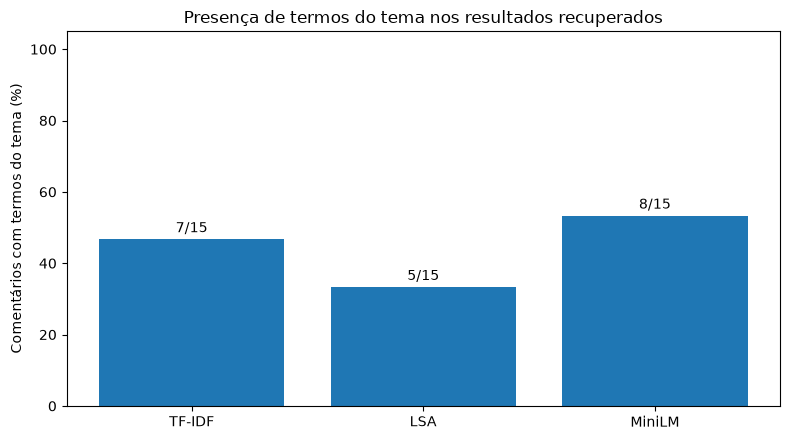

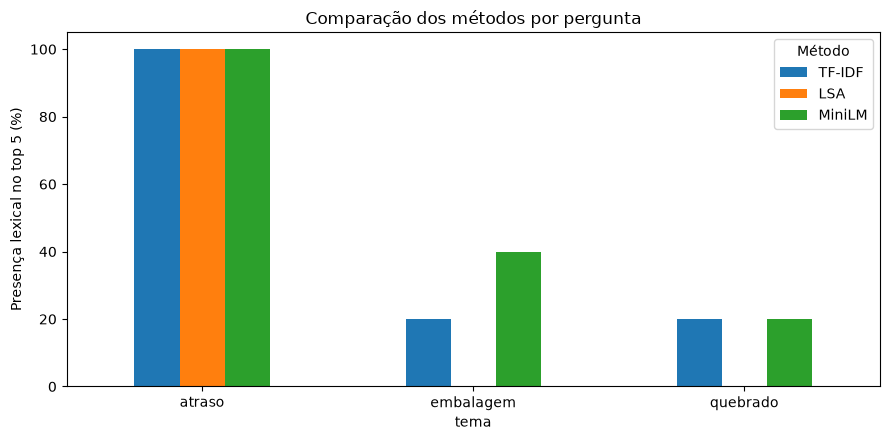

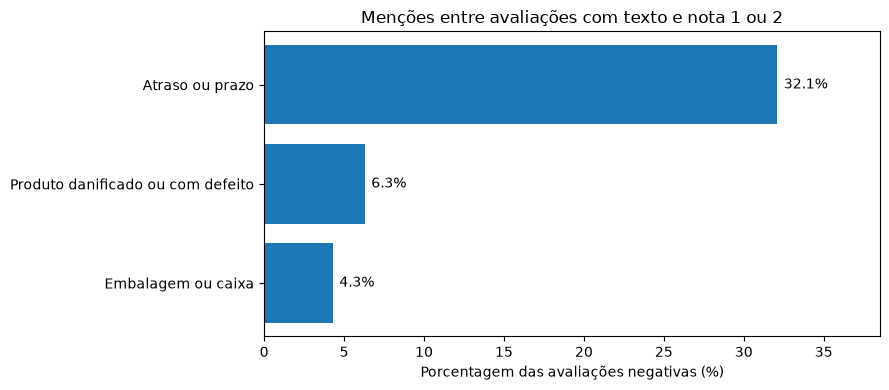

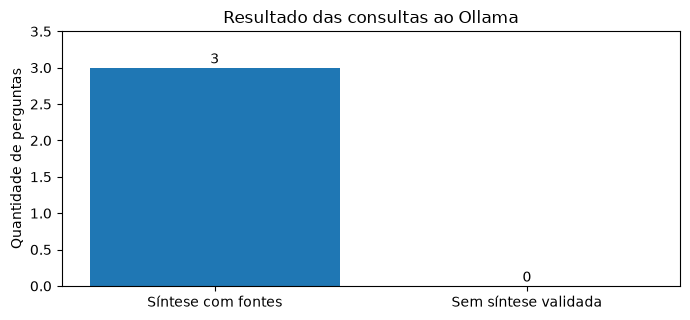

In [21]:
# Os gráficos utilizam as tabelas calculadas acima; nada foi digitado como resultado fixo.
import matplotlib.pyplot as plt

ordem_metodos = ['TF-IDF', 'LSA', 'MiniLM']
metodos_visiveis = [m for m in ordem_metodos if m in set(comparacao['metodo'])]
resumo_graf = resumo_buscas.set_index('metodo').reindex(metodos_visiveis)

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(resumo_graf.index, resumo_graf['proporcao_lexical_pct'])
ax.set(title='Presença de termos do tema nos resultados recuperados',
       ylabel='Comentários com termos do tema (%)', ylim=(0, 105))
for barra, (_, linha) in zip(barras, resumo_graf.iterrows()):
    ax.text(barra.get_x() + barra.get_width()/2, barra.get_height() + 2,
            f"{int(linha['com_termos'])}/{int(linha['comentarios'])}", ha='center')
plt.tight_layout()
plt.savefig(RAIZ / 'results' / 'grafico_comparacao_metodos.png', dpi=150, bbox_inches='tight')
plt.show()

comparacao_graf = comparacao.pivot(index='tema', columns='metodo', values='proporcao_lexical_pct')
comparacao_graf = comparacao_graf.reindex(columns=metodos_visiveis)
ax = comparacao_graf.plot(kind='bar', figsize=(9, 4.5), rot=0)
ax.set(title='Comparação dos métodos por pergunta', ylabel='Presença lexical no top 5 (%)', ylim=(0, 105))
ax.legend(title='Método')
plt.tight_layout()
plt.savefig(RAIZ / 'results' / 'grafico_comparacao_por_tema.png', dpi=150, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(temas_negativos['tema'], temas_negativos['percentual_das_negativas'])
ax.invert_yaxis()
ax.set(title='Menções entre avaliações com texto e nota 1 ou 2',
       xlabel='Porcentagem das avaliações negativas (%)')
for i, valor in enumerate(temas_negativos['percentual_das_negativas']):
    ax.text(valor + 0.4, i, f'{valor:.1f}%', va='center')
ax.set_xlim(0, max(temas_negativos['percentual_das_negativas'].max() * 1.20, 5))
plt.tight_layout()
plt.savefig(RAIZ / 'results' / 'grafico_mencoes_negativas.png', dpi=150, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.3))
rotulos = ['Síntese com fontes', 'Sem síntese validada']
quantidades = [int(avaliacao_ollama['modo'].eq('RAG com Ollama').sum()),
               int(avaliacao_ollama['modo'].ne('RAG com Ollama').sum())]
barras = ax.bar(rotulos, quantidades)
ax.set(title='Resultado das consultas ao Ollama', ylabel='Quantidade de perguntas',
       ylim=(0, max(len(avaliacao_ollama)+0.5, 1)))
for barra, valor in zip(barras, quantidades):
    ax.text(barra.get_x()+barra.get_width()/2, valor+0.06, str(valor), ha='center')
plt.tight_layout()
plt.savefig(RAIZ / 'results' / 'grafico_status_ollama.png', dpi=150, bbox_inches='tight')
plt.show()


## 19.2 Insights que mudam conforme a execução

Esta leitura usa os números recém-calculados. Ela distingue menção por palavras, atraso obtido pelas datas e respostas do Ollama.


In [22]:
from IPython.display import Markdown, display

melhor = resumo_buscas.sort_values('proporcao_lexical_pct', ascending=False).iloc[0]
mais_mencionado = temas_negativos.iloc[0]
qtd_respostas = int(avaliacao_ollama['modo'].eq('RAG com Ollama').sum())
texto_atual = (
    f"**Comparação de busca.** Entre as três perguntas deste experimento, "
    f"{melhor['metodo']} encontrou termos dos temas em {int(melhor['com_termos'])} de "
    f"{int(melhor['comentarios'])} comentários ({melhor['proporcao_lexical_pct']:.1f}%). "
    "Isso não é precisão de recuperação: um comentário pode ser relevante sem conter esses termos.\n\n"
    f"**Avaliações negativas.** O tema com mais menções foi {mais_mencionado['tema'].lower()}, "
    f"identificado em {int(mais_mencionado['avaliacoes_com_mencao']):,} avaliações "
    f"({mais_mencionado['percentual_das_negativas']:.1f}% das {len(negativas):,} negativas com texto). "
    "Essas contagens podem se sobrepor e dependem das expressões buscadas.\n\n"
    f"**Geração.** O Ollama teve {qtd_respostas} sínteses aceitas nas verificações automáticas "
    f"em {len(avaliacao_ollama)} perguntas. "
    + ("É necessário conferir o conteúdo de cada síntese com os comentários citados: nenhum teste automático garante fidelidade integral."
       if qtd_respostas else "As evidências foram recuperadas, mas ainda não há sínteses aceitas para comparar.")
)
display(Markdown(texto_atual))
(RAIZ / 'results' / 'insights_graficos_execucao.md').write_text(
    '# Insights dos gráficos desta execução\n\n' + texto_atual + '\n', encoding='utf-8')


**Comparação de busca.** Entre as três perguntas deste experimento, MiniLM encontrou termos dos temas em 8 de 15 comentários (53.3%). Isso não é precisão de recuperação: um comentário pode ser relevante sem conter esses termos.

**Avaliações negativas.** O tema com mais menções foi atraso ou prazo, identificado em 3,520 avaliações (32.1% das 10,971 negativas com texto). Essas contagens podem se sobrepor e dependem das expressões buscadas.

**Geração.** O Ollama teve 3 sínteses aceitas nas verificações automáticas em 3 perguntas. É necessário conferir o conteúdo de cada síntese com os comentários citados: nenhum teste automático garante fidelidade integral.

705

## 20. Síntese 

Esta seção gera uma leitura final com base nos resultados efetivamente calculados. Ela mantém separados os indicadores de **preparação**, **busca**, **menções nos textos** e **geração**. Ao executar novamente, a análise será atualizada e salva em `results/insights_execucao.md`.

In [23]:
# Texto final baseado nas tabelas da própria execução, sem resultados fixos.
from IPython.display import display, Markdown

totais = {linha['metodo']: linha for _, linha in resumo_buscas.iterrows()}
topico = temas_negativos.iloc[0]
n_geradas = int(avaliacao_ollama['modo'].eq('RAG com Ollama').sum())
n_validas = int(avaliacao_ollama['citacoes_validas'].sum())
n_tentativas = len(avaliacao_ollama)
n_com_data = len(com_data)
n_atraso = int(com_data['dias_atraso'].gt(0).sum()) if n_com_data else 0
nomes = ['TF-IDF', 'LSA', 'MiniLM']

linhas = [
    '# Leitura dos resultados desta execução',
    '',
    '## Preparação e relacionamentos',
    f'A partir de {len(avaliacoes):,} avaliações originais, foram mantidas {len(documentos):,} com texto. '
    f'Os relacionamentos preservaram {len(pedidos_completos):,} pedidos. '
    'Essa verificação mostra que os cruzamentos não multiplicaram a tabela central de pedidos.',
    '',
    '## Comparação entre as buscas',
    'Os três métodos foram consultados com as mesmas perguntas, cinco resultados por pergunta e filtro de nota até 2.',
]
for nome in nomes:
    if nome in totais:
        t = totais[nome]
        linhas.append(f'- {nome}: {int(t["com_termos"])} de {int(t["comentarios"])} comentários '
                      f'com expressões do tema ({float(t["proporcao_lexical_pct"]):.1f}%).')
linhas.extend([
    'Esse indicador registra presença de palavras selecionadas; não corresponde a precisão semântica '
    'nem demonstra que um modelo é melhor em qualquer contexto.',
    '',
    '### Diferenças por pergunta',
])
for tema, _pergunta, _termos in perguntas_teste:
    partes = []
    for nome in nomes:
        base = comparacao.loc[(comparacao['tema'] == tema) & (comparacao['metodo'] == nome)]
        if not base.empty:
            linha = base.iloc[0]
            partes.append(f'{nome}: {int(linha["com_termos_do_tema"])}/{int(linha["retornados"])}')
    linhas.append(f'- **{tema.capitalize()}** — ' + '; '.join(partes) + '.')
linhas.extend([
    'Na pergunta sobre produtos quebrados, comentários sobre defeito podem ser pertinentes sem conter '
    'as raízes específicas usadas na contagem. É preciso ler as evidências antes de julgar a qualidade da busca.',
    '',
    '## Avaliações negativas',
    f'Foram encontradas {len(negativas):,} avaliações com texto e nota 1 ou 2.',
])
for _, linha in temas_negativos.iterrows():
    linhas.append(f'- {linha["tema"]}: {int(linha["avaliacoes_com_mencao"]):,} menções '
                  f'({float(linha["percentual_das_negativas"]):.1f}% das avaliações negativas com texto).')
if n_com_data:
    linhas.append(f'Entre {n_com_data:,} avaliações negativas com datas suficientes, '
                  f'{n_atraso:,} ({100*n_atraso/n_com_data:.1f}%) tiveram entrega após a data estimada.')
linhas.extend([
    'Menções e atrasos calculados são medidas diferentes, com denominadores diferentes. '
    'Os temas podem coexistir e não é possível atribuir causalidade a partir dessas contagens.',
    '',
    '## Geração com Ollama',
    f'Houve {n_geradas} respostas que passaram pelas verificações automáticas e foram registradas como RAG com Ollama em {n_tentativas} tentativas. '
    f'Dessas, {n_validas} tiveram marcadores de citação aceitos pelo verificador.',
])
if n_geradas == 0:
    linhas.append('Nesta execução, o sistema recuperou evidências, mas nenhuma síntese foi registrada '
                  'como resposta válida do Ollama. Portanto, não há base para comparar a qualidade '
                  'das respostas geradas.')
else:
    linhas.append('A verificação automática confere referências e algumas negações contraditórias, mas não garante fidelidade integral. As referências existem entre '
                  'as fontes recuperadas; é necessário revisar a fidelidade de cada afirmação.')
linhas.extend(['', '## Limites',
                'Os dados são históricos, as contagens por palavras são exploratórias e '
                'as evidências do top 5 não representam toda a população de pedidos.'])

texto_insights = '\n'.join(linhas) + '\n'
(RAIZ / 'results').mkdir(exist_ok=True)
(RAIZ / 'results' / 'insights_execucao.md').write_text(texto_insights, encoding='utf-8')
display(Markdown(texto_insights))

# Leitura dos resultados desta execução

## Preparação e relacionamentos
A partir de 99,224 avaliações originais, foram mantidas 42,343 com texto. Os relacionamentos preservaram 99,441 pedidos. Essa verificação mostra que os cruzamentos não multiplicaram a tabela central de pedidos.

## Comparação entre as buscas
Os três métodos foram consultados com as mesmas perguntas, cinco resultados por pergunta e filtro de nota até 2.
- TF-IDF: 7 de 15 comentários com expressões do tema (46.7%).
- LSA: 5 de 15 comentários com expressões do tema (33.3%).
- MiniLM: 8 de 15 comentários com expressões do tema (53.3%).
Esse indicador registra presença de palavras selecionadas; não corresponde a precisão semântica nem demonstra que um modelo é melhor em qualquer contexto.

### Diferenças por pergunta
- **Atraso** — TF-IDF: 5/5; LSA: 5/5; MiniLM: 5/5.
- **Quebrado** — TF-IDF: 1/5; LSA: 0/5; MiniLM: 1/5.
- **Embalagem** — TF-IDF: 1/5; LSA: 0/5; MiniLM: 2/5.
Na pergunta sobre produtos quebrados, comentários sobre defeito podem ser pertinentes sem conter as raízes específicas usadas na contagem. É preciso ler as evidências antes de julgar a qualidade da busca.

## Avaliações negativas
Foram encontradas 10,971 avaliações com texto e nota 1 ou 2.
- Atraso ou prazo: 3,520 menções (32.1% das avaliações negativas com texto).
- Produto danificado ou com defeito: 691 menções (6.3% das avaliações negativas com texto).
- Embalagem ou caixa: 475 menções (4.3% das avaliações negativas com texto).
Entre 9,354 avaliações negativas com datas suficientes, 2,784 (29.8%) tiveram entrega após a data estimada.
Menções e atrasos calculados são medidas diferentes, com denominadores diferentes. Os temas podem coexistir e não é possível atribuir causalidade a partir dessas contagens.

## Geração com Ollama
Houve 3 respostas que passaram pelas verificações automáticas e foram registradas como RAG com Ollama em 3 tentativas. Dessas, 3 tiveram marcadores de citação aceitos pelo verificador.
A verificação automática confere referências e algumas negações contraditórias, mas não garante fidelidade integral. As referências existem entre as fontes recuperadas; é necessário revisar a fidelidade de cada afirmação.

## Limites
Os dados são históricos, as contagens por palavras são exploratórias e as evidências do top 5 não representam toda a população de pedidos.


## 21. Conclusão e limites

O projeto relaciona as avaliações aos pedidos e permite consultar comentários específicos com identificadores rastreáveis. Na comparação, a medida de presença lexical oferece um primeiro indício sobre a busca.

O RAG também exige uma checagem própria: reconhecer `[E1]` não prova que o modelo interpretou bem `[E1]`. A versão atual rejeita algumas contradições explícitas, apresenta o motivo da rejeição e mantém as evidências para leitura. 

Os gráficos e os arquivos de `results/` são recalculados ao executar o notebook.
